# Gaseous transmittance

This tutorial computes the direct transmittance of the absorbing gases of the atmosphere
(water vapour, ozone, nitrogen dioxide, methane and the well-mixed gases) with
{py:class}`~radcalnet_oc.kernel.GaseousTransmittance`, and shows how it is seen by sensors of
different spectral resolutions.

For a path of air mass $m$, the transmittance of a gas $g$ of total column $U_g$ is
(Eq. {eq}`tgas` of the {doc}`../methods` page)

$$
T_g(\lambda) = \exp\left[ -m\, c_g\, U_g\, \kappa_g(\lambda) \right],
$$

where $\kappa_g$ is the absorption optical thickness per unit column given by the look-up table and
$c_g$ a scaling coefficient (1 by default). The optical thickness of the background gases
($CO$, $CO_2$, $O_2$, $O_4$) is scaled with the surface pressure (Eq. {eq}`tgas_bg`), and the total
transmittance is the product of the transmittances of all the gases (Eq. {eq}`tgas_tot`).

In [1]:
import logging

import matplotlib as mpl
import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import xarray as xr

import radcalnet_oc as radoc
# radcalnet_oc sets the root logger to INFO: show only the warnings in this tutorial
logging.getLogger().setLevel(logging.WARNING)
print(f'radcalnet_oc: {radoc.__version__}')

radcalnet_oc: 1.1.0


## Load the look-up tables

{py:class}`~radcalnet_oc.lut.LUT` loads, among others, the look-up table of the gaseous absorption
(`gas_lut`): the normalized absorption optical thickness $\kappa_g(\lambda)$ of each gas at the full
spectral resolution of the simulations (wavelengths in nm).

In [2]:
lut = radoc.LUT()
lut.gas_lut

<xarray.Dataset> Size: 2MB
Dimensions:  (wl: 21687)
Coordinates:
  * wl       (wl) float64 173kB 349.9 350.1 350.3 ... 2.599e+03 2.6e+03
Data variables:
    ch4      (wl) float64 173kB ...
    co       (wl) float64 173kB ...
    co2      (wl) float64 173kB ...
    h2o      (wl) float64 173kB ...
    n2o      (wl) float64 173kB ...
    no2      (wl) float64 173kB ...
    o2       (wl) float64 173kB ...
    o3       (wl) float64 173kB ...
    o4       (wl) float64 173kB ...
Attributes:
    description:           Absorption optical thickness of some atmospheric g...
    atmospheric pressure:  1000 hPa

## Atmospheric composition and geometry

The gas columns are given in kg m$^{-2}$. The usual units are converted as follows:

| Gas | Usual unit | Conversion to kg m$^{-2}$ |
|---|---|---|
| water vapour | precipitable water (cm) | $\times 10$ |
| ozone | Dobson unit (DU) | $\times 2.14485\cdot10^{-5}$ |
| nitrogen dioxide | µmol m$^{-2}$ | $\times 46.0\cdot10^{-9}$ (molar mass 46 g mol$^{-1}$) |

The air mass of the Sun-surface-sensor path is $m = 1/\cos\theta_s + 1/\cos\theta_v$, with
$\theta_s$ (`sza`) and $\theta_v$ (`vza`) the solar and viewing zenith angles.

In [3]:
sza=40
vza=0
pressure=1000

#water vapor in cm
tpw_cm=2.6

#ozone in dobson
to3_du=300 

#NO2 (micromol.m-2)
tcno2_micmol_m2=100

# ch4 in kg.m-2
tcch4= 1e-2

# unit conversion
# tcwv cm into kg.m-2
tcwv=tpw_cm*10 

# conversion O3 du to kg.m-2
tco3=to3_du *2.14485e-5

# conversion NO2 micromol.m-2 into kg.m-2
tcno2=tcno2_micmol_m2*46.0e-9
tcno2

4.6e-06

## Spectral transmittance

The transmittance of the direct beam `Ttot` is computed for the air mass of the Sun-surface-sensor path.
The O$_2$-B and O$_2$-A bands are computed line by line (`o2_model='lbl'`, default since version 1.1), the
other gases with the REPTRAN tables; `Ttot_reptran` uses REPTRAN for O$_2$ too, as before version 1.1.

The direct-beam transmittance is exact for the direct light only. The light scattered by the molecules
and aerosols does not cross the same amount of absorber: the path reflectance sees a shorter path (the
photons scattered above the water vapour skip it), the water-leaving term a slightly longer one (the
skylight reaching the surface). Since version 1.1, the transmittance of each term of the signal is given
by a photon path-length model fitted on radiative transfer simulations of the coupled absorption and
scattering, in the O$_2$ and H$_2$O bands of 684-990 nm
({py:meth}`get_coupled_transmittance <radcalnet_oc.kernel.GaseousTransmittance.get_coupled_transmittance>`,
{ref}`methods-gas-coupling`): `Tg_atm` for the path reflectance and `Tg_w` for the water-leaving term,
here for an aerosol optical thickness of 0.1 at 550 nm.

In [4]:
from radcalnet_oc.kernel import GasCoupling, GAS_COUPLING_PPLD_FILE

air_mass = 1. / np.cos(np.radians(sza)) + 1. / np.cos(np.radians(vza))
aot550 = 0.1


def gaseous_transmittance(o2_model='lbl'):
    gas_trans = radoc.GaseousTransmittance(lut.gas_lut, o2_model=o2_model)
    gas_trans.air_mass = air_mass
    gas_trans.pressure = pressure
    gas_trans.gas_tc['h2o'] = tcwv
    gas_trans.gas_tc['o3'] = tco3
    gas_trans.gas_tc['ch4'] = tcch4
    gas_trans.gas_tc['no2'] = tcno2
    return gas_trans


# direct beam, line-by-line O2 (default) and REPTRAN O2
gas_trans = gaseous_transmittance()
Ttot = gas_trans.get_gaseous_transmittance()
Ttot_reptran = gaseous_transmittance('reptran').get_gaseous_transmittance()

# path reflectance and water-leaving term, absorption coupled with the scattering
coupling = GasCoupling(GAS_COUPLING_PPLD_FILE)
Tg_atm = gas_trans.get_coupled_transmittance(air_mass, 'atm', aot550, coupling)
Tg_w = gas_trans.get_coupled_transmittance(air_mass, 'w', aot550, coupling)

## Plot the results

Direct beam at full resolution over the whole spectrum (top left), then the transmittances convolved with
Gaussian responses of 3 nm FWHM, so that the terms can be compared: direct beam (black), path reflectance
(blue), water-leaving term (orange) and direct beam with the REPTRAN O$_2$ (red, dashed), in the O$_2$-B,
H$_2$O 720 nm and O$_2$-A bands (680--780 nm) and in the near-infrared water vapour bands (800--1000 nm).
The path reflectance is much less absorbed than the direct beam, the water-leaving term slightly more.
Bottom right: ratio of the coupled transmittances to the direct beam; outside 684--990 nm, all the
terms see the direct-beam transmittance.

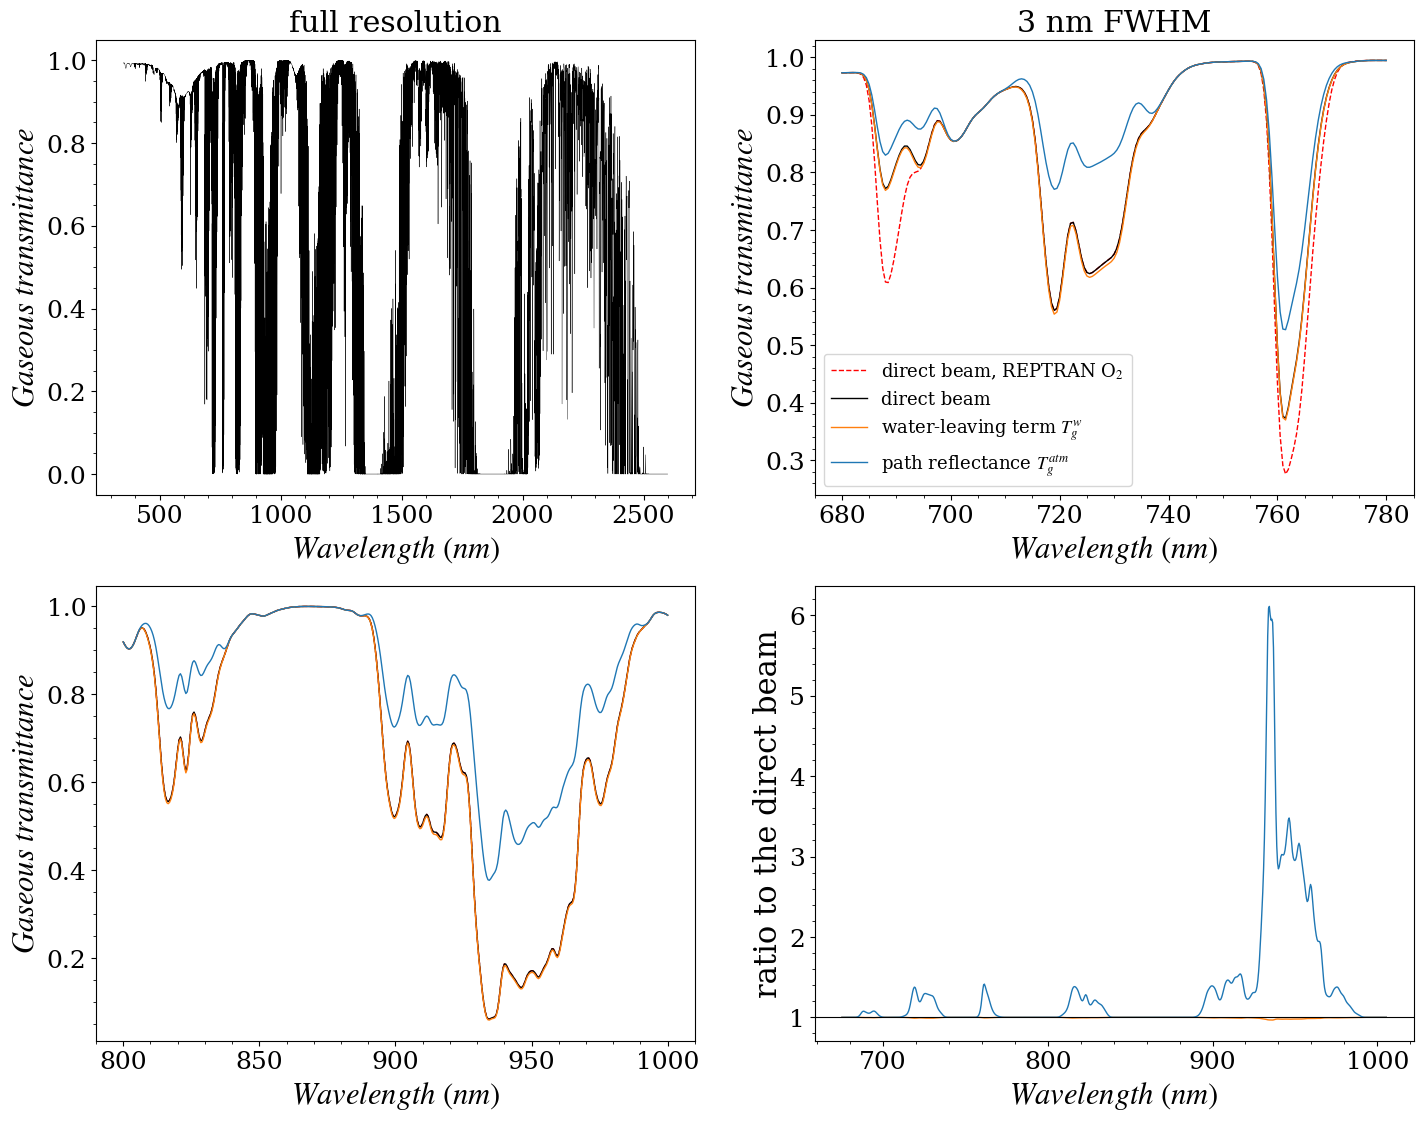

In [5]:
spectral_3nm = radoc.Spectral(central_wl=np.arange(675., 1006., 0.5), fwhm=3.)


def smooth(T):
    '''Transmittance convolved with Gaussian responses of 3 nm FWHM.'''
    out = spectral_3nm.convolve2(T.rename('T'), expon=2)
    return out[list(out.data_vars)[0]] if isinstance(out, xr.Dataset) else out


curves = [(Ttot_reptran, dict(c='r', ls='--', label='direct beam, REPTRAN O$_2$')),
          (Ttot, dict(c='k', label='direct beam')),
          (Tg_w, dict(c='tab:orange', label=r'water-leaving term $T_g^{w}$')),
          (Tg_atm, dict(c='tab:blue', label=r'path reflectance $T_g^{atm}$'))]
smoothed = [(smooth(T), kw) for T, kw in curves]

fig, axs = plt.subplots(2, 2, figsize=(17, 13))
axs = axs.ravel()
Ttot.plot(lw=0.3, ax=axs[0], c='k')
for ax, wl_range in zip(axs[1:3], [slice(680, 780), slice(800, 1000)]):
    for T, kw in smoothed:
        T.sel(wl=wl_range).plot(lw=1, ax=ax, **kw)
Tdirect = smoothed[1][0]
for T, kw in smoothed[2:]:
    (T / Tdirect).plot(lw=1, ax=axs[3], **kw)
axs[3].axhline(1, c='k', lw=0.8)
axs[3].set_ylabel('ratio to the direct beam')
for ax in axs[:3]:
    ax.set_ylabel(r'$Gaseous\ transmittance$')
for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_title('')
    ax.minorticks_on()
axs[0].set_title('full resolution')
axs[1].set_title('3 nm FWHM')
axs[1].legend(fontsize=13, loc='lower left')

## Impact of the spectral resolution of the sensor

A sensor band $b$ integrates the hyperspectral signal $X(\lambda)$ over its spectral response
$S_b$ (Eq. {eq}`convolution`):

$$
X_b = \frac{\int X(\lambda)\, S_b(\lambda)\, d\lambda}{\int S_b(\lambda)\, d\lambda}.
$$

The spectral responses are modelled here as Gaussian functions centred on the central wavelengths
`central_wl`, of standard deviation $\sigma = \mathrm{FWHM}/(2\sqrt{2\ln 2})$, computed from the
full width at half maximum `fwhm` (nm), with {py:meth}`Spectral.convolve <radcalnet_oc.lut.Spectral.convolve>`
(see {ref}`spectral_convolution`). The narrow absorption lines are smoothed out as the bands get
wider.

 364. 365.] nm truncated by the wavelength range of the signal (349.926-2599.77 nm)


 364. 365. 366. 367. 368. 369. 370. 371. 372. 373. 374. 375. 376. 377.
 378. 379. 380. 381. 382. 383. 384. 385. 386. 387. 388. 389. 390. 391.
 392. 393. 394. 395. 396. 397.] nm truncated by the wavelength range of the signal (349.926-2599.77 nm)


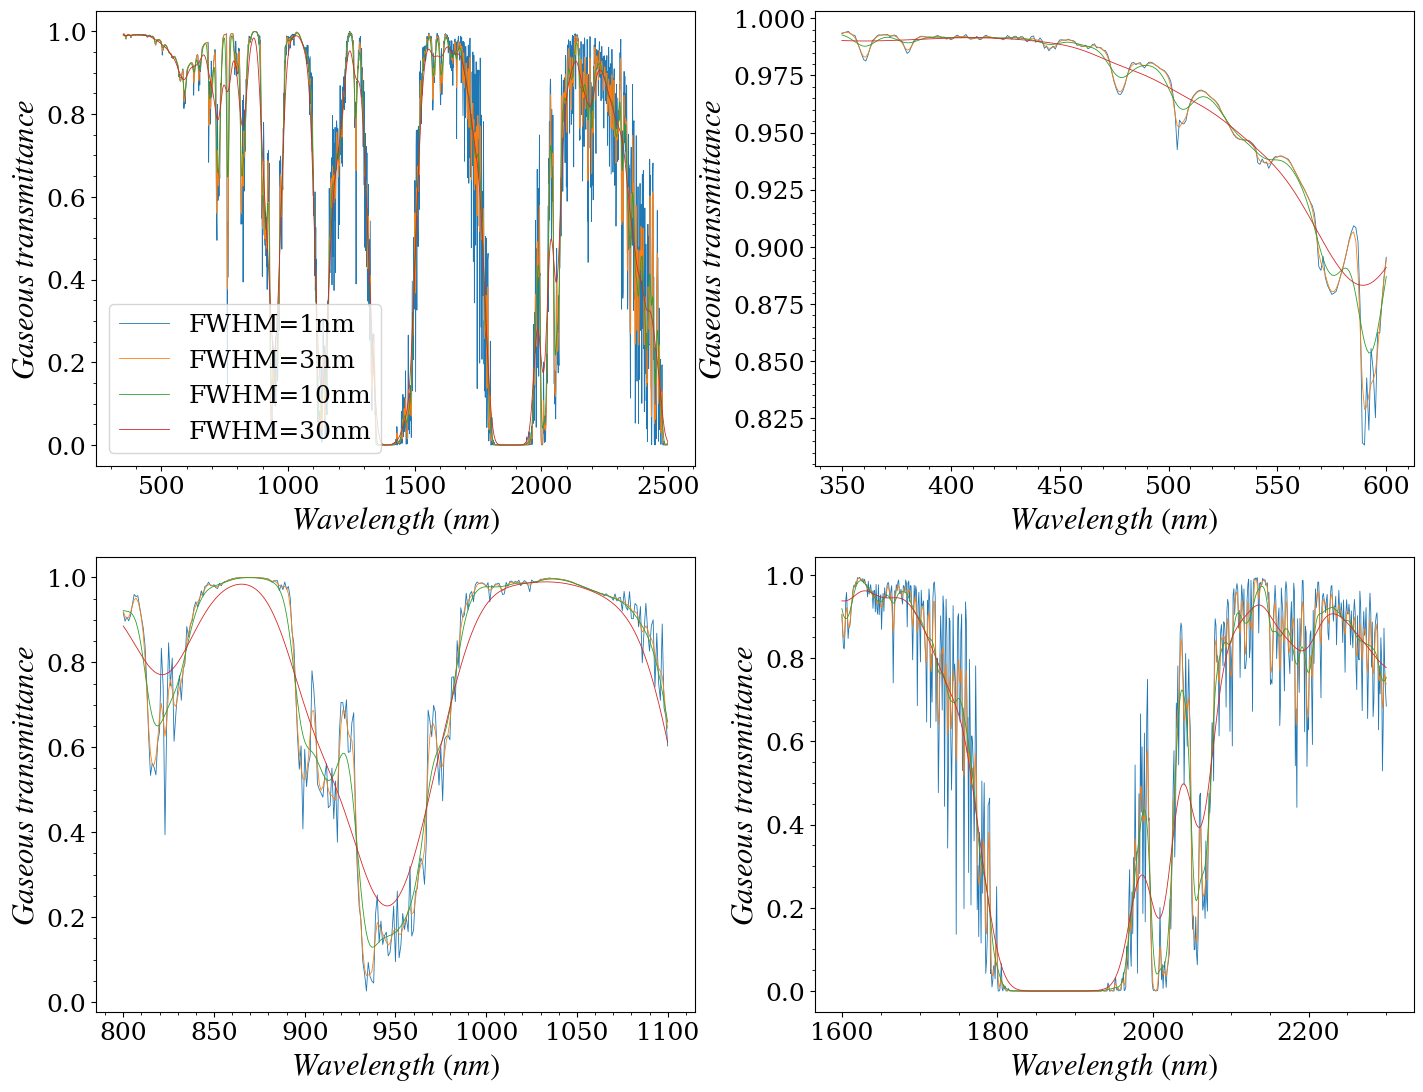

In [6]:
spectral_res=1
central_wl=np.arange(350,2500,spectral_res)
wl_range=slice(500,780)

signal = Ttot
wl_signal = signal.wl.values

fig,axs = plt.subplots(2,2,figsize=(17,13))
axs=axs.ravel()

for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    Tg = spectral.convolve(signal)
    Tg.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs[0])
    
    wl_range=slice(350,600)
    Tg.sel(wl=wl_range).plot(lw=0.6,ax=axs[1])
    
    wl_range=slice(800,1100)
    Tg.sel(wl=wl_range).plot(lw=0.6,ax=axs[2])
    wl_range=slice(1600,2300)
    Tg.sel(wl=wl_range).plot(lw=0.6,ax=axs[3])
    
for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()
axs[0].legend()

## Absorption of each gas

Extinction $1 - T_g$ of each gas for one air mass ($m = 1$) and the columns set above (columns of 1
for the background gases), averaged over 5 spectral points (REPTRAN tables, O$_2$ included). Top: full spectrum (log scale); bottom:
visible and near infrared.

[]

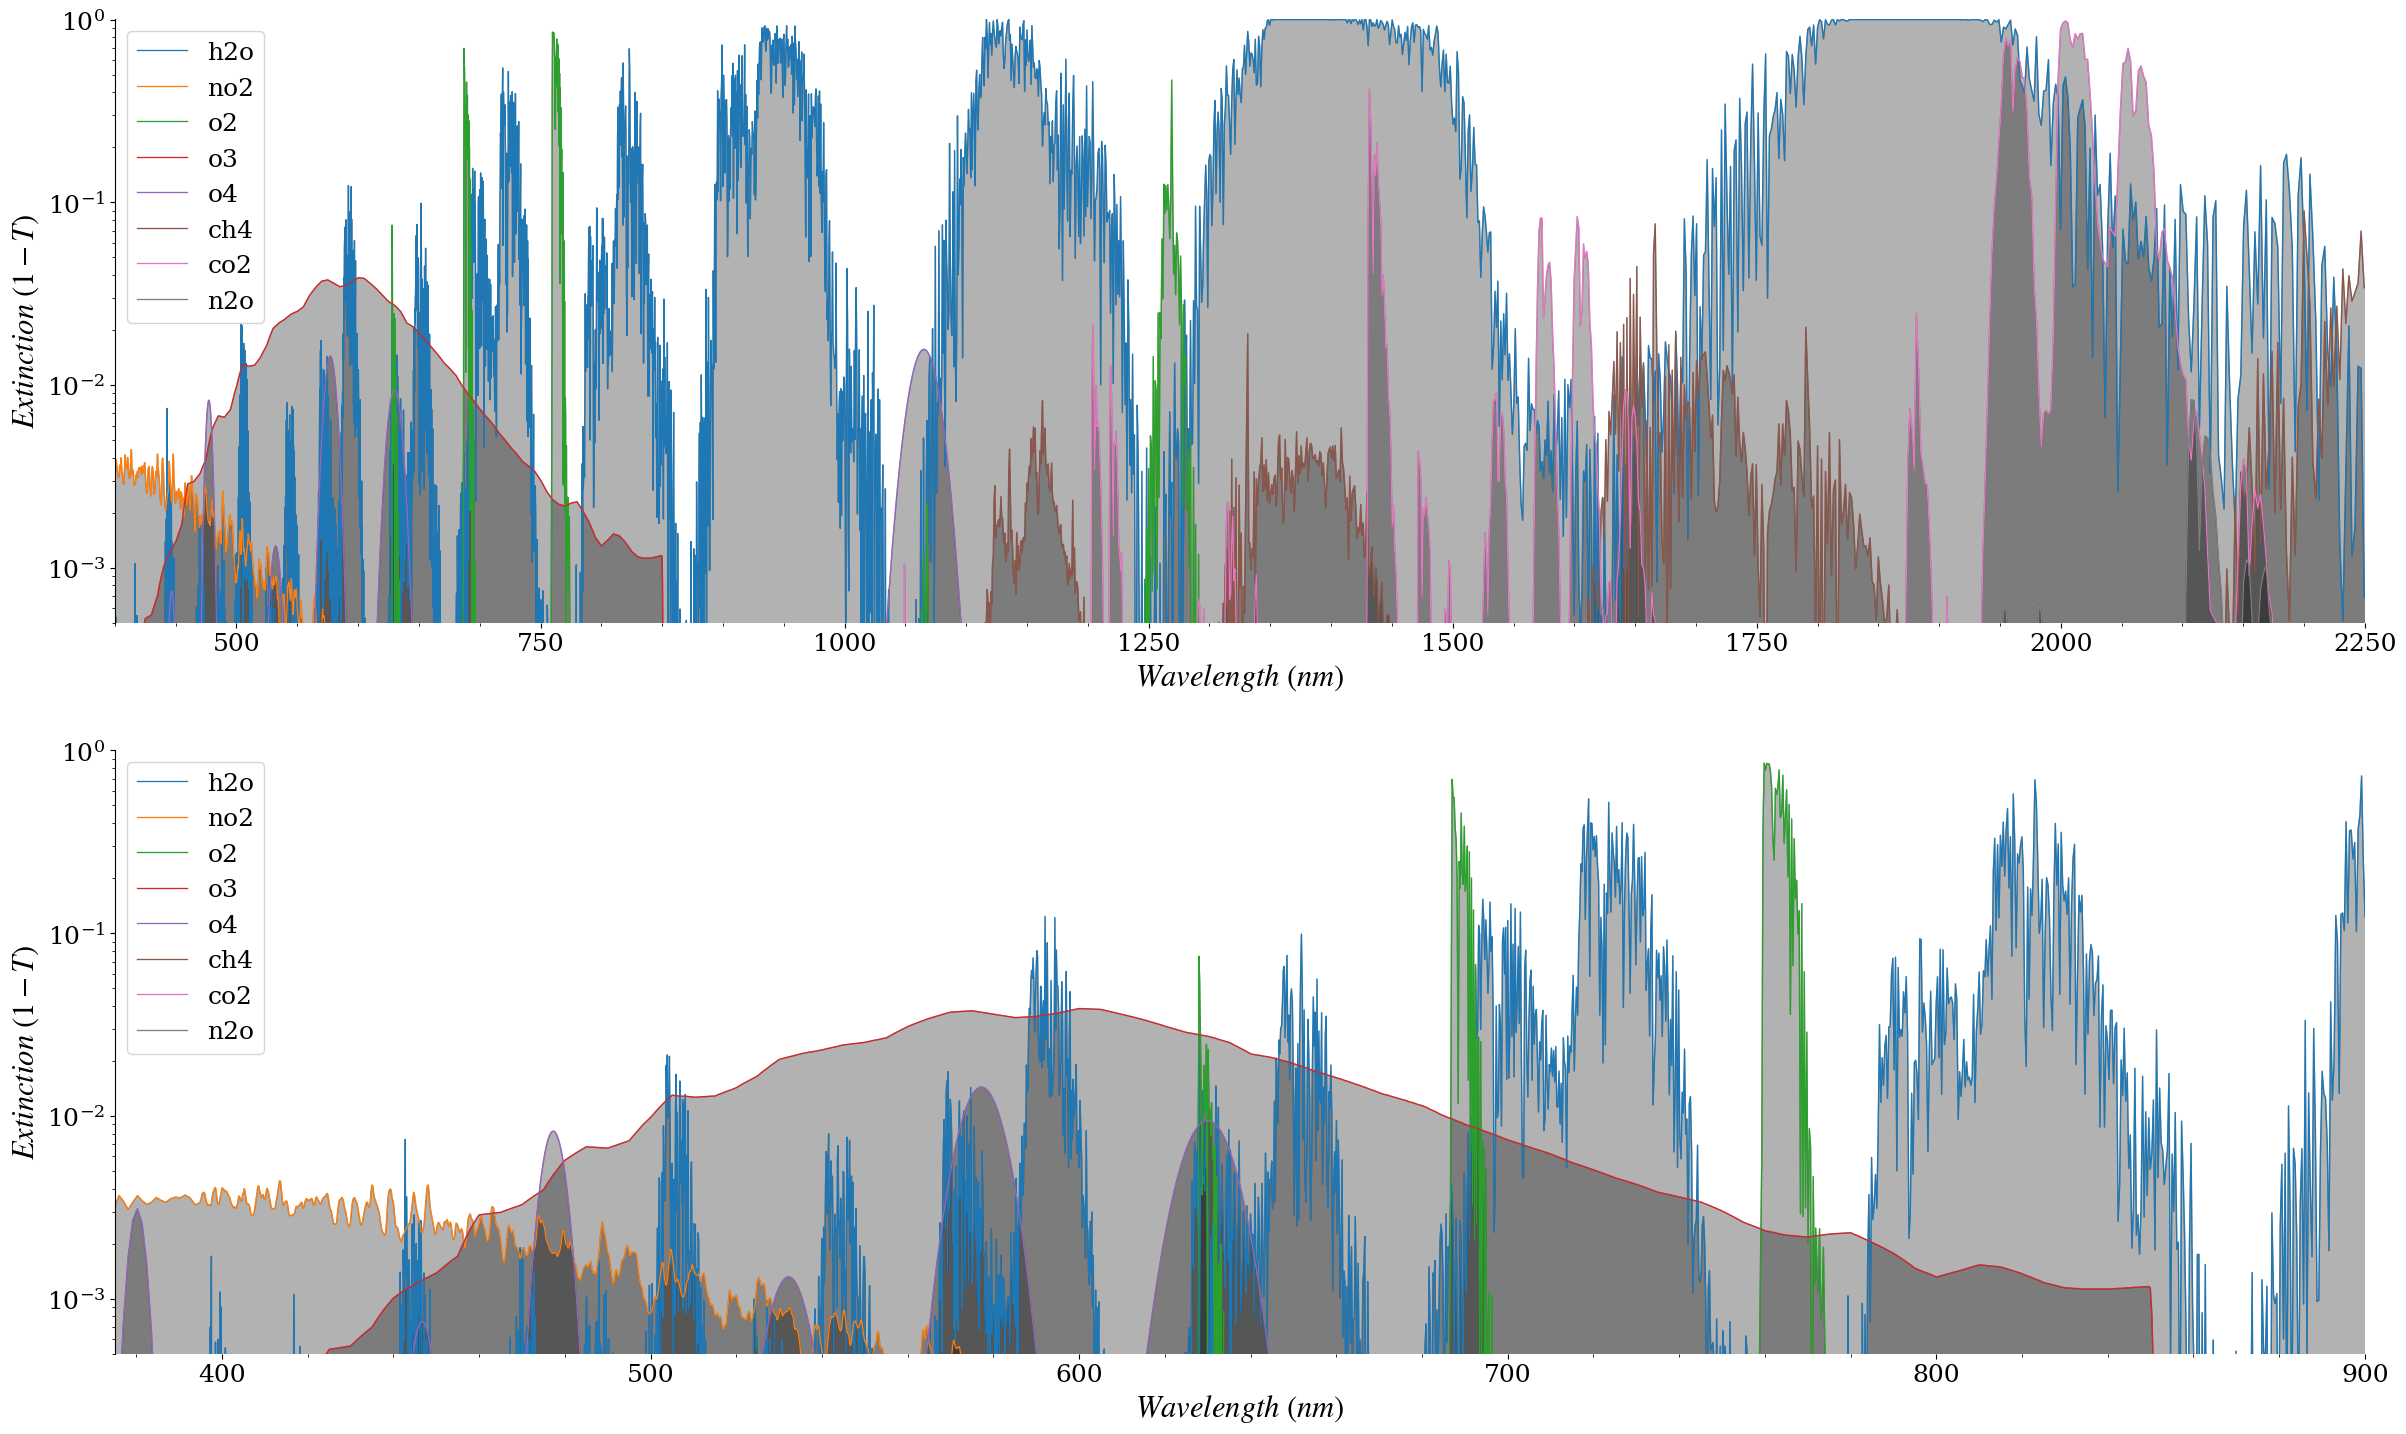

In [7]:
M=1./np.cos(np.radians(sza))+1./np.cos(np.radians(vza))
variable='o4'
variables=['h2o','no2','o2','o3','o4','ch4','co2','n2o']
conc={'ch4':tcch4,'co':1,'co2':1,
      'h2o':tcwv,'n2o':1,'no2':tcno2,
      'o2':1,'o3':tco3,'o4':1}



fig, axs = plt.subplots(nrows=2, sharey=True, figsize=(25, 15))
fig.subplots_adjust(bottom=0.05, top=0.94, left=0.05, right=0.95, hspace=0.21, wspace=0.025)
for iax in range(2):
    for i, variable in enumerate(variables):
        abs_ot = gas_trans.gas_lut[variable]*conc[variable]
        Tg = np.exp(-abs_ot).coarsen(wl=5,boundary='pad').mean()
        axs[iax].minorticks_on()
        axs[iax].spines[['right', 'bottom', 'top']].set_visible(False)
        axs[iax].fill_between(Tg.wl,
                              1 - Tg, color='k', alpha=0.3)
        axs[iax].plot(Tg.wl,
                      1 - Tg,  lw=0.95,label=variable)
   
    axs[iax].set_xlabel(r'$Wavelength\ (nm)$')
    axs[iax].legend()



for i in range(2):
    axs[i].set_ylabel(r'$Extinction\ (1-T)$')

axs[0].set_xlim([400, 2250])
axs[1].set_xlim([375, 900])
axs[0].set_ylim([0.0005, 1.01])
axs[0].semilogy()